# 07 — Logistic Regression

> Predicting the *probability* of a yes/no outcome — and the first model in this repository that learns by gradient descent.

The summary of this lesson is in [README.md](README.md). This notebook is the
full working: the reasoning, the code, and the results.

This lesson is built to be learned from, not just read. The mathematics comes in
small steps, each followed by the line of code that does the same thing, and the
cells marked **Try it yourself** have a setting you can change and re-run to see
what happens.

**Contents**

1. The problem
2. Intuition
3. The mathematics — in five small steps
4. The data
5. Modeling — gradient descent by hand, then scikit-learn
6. Results and interpretation
7. References

## 1. The problem

A telecom company is losing customers to competitors. Keeping a customer is
cheaper than winning a new one, so the company wants to know **which customers
are about to leave** — to *churn* — while there is still time to offer them
something.

For each customer we know how long they have been a customer, their age, income,
education, years at their address and with their employer, and whether they rent
equipment. The answer is yes (churned) or no (stayed).

What the company really wants is not a hard yes/no but a **probability**: "this
customer has a 70% chance of leaving" is something a retention team can rank and
act on. Logistic regression gives exactly that.

## 2. Intuition

**Start from what we already know.** Linear regression (lessons 01–02) computes a
weighted sum of the features — a *score*. A higher score could mean "more likely
to churn". The trouble is that a score can be anything: −3, 0.4, 17. A
probability must stay between 0 and 1.

**The fix is one extra step: squash the score.** Logistic regression takes the
same weighted sum and passes it through the **sigmoid** function, an S-shaped
curve that turns any number into a value between 0 and 1:

- a very negative score → a probability near 0,
- a score of exactly 0 → a probability of 0.5,
- a very positive score → a probability near 1.

That is the whole model: **linear score, then squash.** Everything else in this
lesson is about how to find good weights for the score.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

# Fixed seed so the train/test split and the cross-validation folds are the
# same on every run, and the numbers in README.md are the numbers you get.
RANDOM_SEED = 4

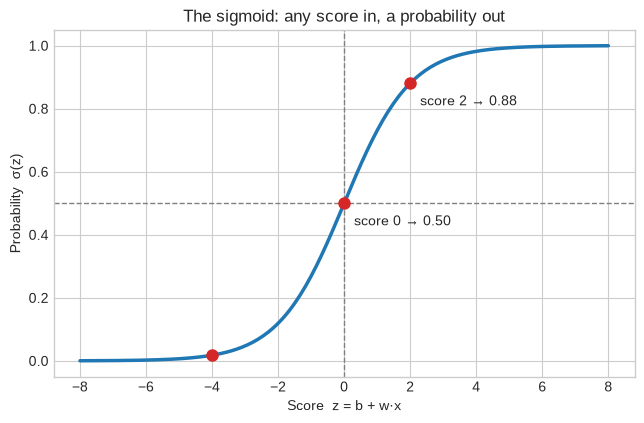

In [2]:
def sigmoid(z):
    # Squash any number into the range (0, 1).
    return 1 / (1 + np.exp(-z))


z = np.linspace(-8, 8, 200)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(z, sigmoid(z), color="tab:blue", linewidth=2.5)
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
for score in [-4, 0, 2]:
    ax.plot(score, sigmoid(score), "o", color="tab:red", markersize=8)
    ax.annotate(f"score {score} → {sigmoid(score):.2f}", (score + 0.3, sigmoid(score) - 0.07))
ax.set_xlabel("Score  z = b + w·x")
ax.set_ylabel("Probability  σ(z)")
ax.set_title("The sigmoid: any score in, a probability out")
plt.show()

## 3. The mathematics — in five small steps

Each step has the formula, what it means in plain words, and the one line of
code that does it.

---

### Step 1 — the score

$$
z = b + w_1 x_1 + w_2 x_2 + \cdots + w_n x_n = b + \mathbf{w} \cdot \mathbf{x}
$$

*In words:* multiply each feature by its weight, add them up, add a starting
value $b$. Identical to linear regression.

*In code:* `z = X @ w + b`

---

### Step 2 — the squash

$$
p = \sigma(z) = \frac{1}{1 + e^{-z}}
$$

*In words:* turn the score into a probability of churning, $p = P(\text{churn} = 1 \mid \mathbf{x})$.

*In code:* `p = sigmoid(z)`

You may also see this written as $\frac{e^{z}}{1 + e^{z}}$ — multiply top and
bottom by $e^{z}$ and it is the same function.

---

### Step 3 — what the weights mean: log-odds

Rearranging step 2 gives

$$
\log \frac{p}{1 - p} = b + \mathbf{w} \cdot \mathbf{x}
$$

$\frac{p}{1-p}$ is the **odds** — a 75% chance is odds of 3 to 1. So the score
is the *log* of the odds, and a weight $w_j$ says: **each extra unit of feature
$j$ multiplies the odds of churning by $e^{w_j}$**. That is how the fitted
weights are read in section 6.

---

### Step 4 — the cost: how wrong is a probability?

A prediction is judged by the probability it gave to **what actually happened**.
If a customer churned and the model said 90%, that is good. If it said 10%, that
is bad — and confidently bad. The cost for one customer is

$$
\text{cost} = -\log(\text{probability given to the true answer})
$$

which, written for both cases at once, is

$$
J(\mathbf{w}, b) = -\frac{1}{m} \sum_{i=1}^{m} \Big[ y^{(i)} \log p^{(i)} + \big(1 - y^{(i)}\big) \log \big(1 - p^{(i)}\big) \Big]
$$

Only one of the two terms is ever switched on: if $y = 1$ it is $-\log p$, if
$y = 0$ it is $-\log(1-p)$. This is called **log loss** (or cross-entropy).

*In code:* `cost = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))`

Why not the squared error from linear regression? Once the sigmoid is inside it,
squared error has a bumpy surface with dips that can trap a search. Log loss is
a single smooth bowl — one bottom, no traps — which is what makes step 5 work.

In [3]:
p_true = np.array([0.99, 0.9, 0.7, 0.5, 0.3, 0.1, 0.01])

pd.DataFrame(
    {
        "probability given to the true answer": p_true,
        "cost  −log(p)": -np.log(p_true),
    }
).round(3)

,probability given to the true answer,cost −log(p)
0,0.99,0.010
1,0.90,0.105
2,0.70,0.357
3,0.50,0.693
4,0.30,1.204
5,0.10,2.303
6,0.01,4.605


Being right with confidence costs almost nothing. A coin-flip 0.5 costs 0.69.
Being **confidently wrong** — 1% on what actually happened — costs 4.6, nearly
seven times as much. Log loss punishes overconfidence hardest, which is exactly
what a model producing probabilities should be punished for.

---

### Step 5 — gradient descent: finding the bottom of the bowl

In lessons 01–03 the best weights came from a formula, solved in one go. Logistic
regression has **no such formula** — the sigmoid makes the equations impossible
to solve directly. So the weights are found by *searching*.

**The picture.** Imagine standing on a hillside in thick fog, trying to reach
the lowest point of the valley. You cannot see the bottom, but you can feel which
way the ground slopes under your feet. So you take a step downhill, feel again,
take another step, and repeat. Eventually the ground is flat: you are at the
bottom.

That is gradient descent. The hillside is the cost $J$; your position is the
current weights; "which way is downhill" is the **gradient**.

**The update rule** — one step:

$$
w_j \leftarrow w_j - \alpha \, \frac{\partial J}{\partial w_j}
\qquad\qquad
b \leftarrow b - \alpha \, \frac{\partial J}{\partial b}
$$

$\alpha$ is the **learning rate**: how big a step to take.

**The slope itself** turns out to be remarkably simple:

$$
\frac{\partial J}{\partial w_j} = \frac{1}{m} \sum_{i=1}^{m} \big( p^{(i)} - y^{(i)} \big) \, x_j^{(i)}
\qquad\qquad
\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} \big( p^{(i)} - y^{(i)} \big)
$$

*In words:* for every customer, take the **error** (predicted probability minus
what really happened) and multiply it by that customer's **feature value**.
Average over all customers. That is the slope.

It reads naturally. If the model under-predicts churn ($p < y$) for customers
with a high value of some feature, the error is negative, the slope is negative,
and subtracting it *raises* that feature's weight. Every customer nudges each
weight in the direction that would have made their own prediction less wrong.

*In code — the whole algorithm is four lines inside a loop:*

```python
p = sigmoid(X @ w + b)          # steps 1 and 2: predict
error = p - y                   # how wrong, for each customer
w = w - alpha * (X.T @ error) / m   # step 5: move each weight downhill
b = b - alpha * error.mean()
```

Section 5 runs exactly this, watches it learn, and checks it against
scikit-learn.

**The learning rate matters.** Too small and the search crawls. Too large and
each step overshoots the bottom and lands higher up the other side — the cost
bounces around or explodes. Section 5 lets you try both.

## 4. The data

Customer records from a telecom company, as supplied with the course: 200
customers, 28 columns.

In [4]:
df = pd.read_csv("data/ChurnData.csv")

print(df.shape)
print("missing values:", df.isna().sum().sum())
df.head()

(200, 28)
missing values: 0


,tenure,age,address,income,ed,employ,equip,callcard,wireless,longmon,...,pager,internet,callwait,confer,ebill,loglong,logtoll,lninc,custcat,churn
0,11.0,33.0,7.0,136.0,5.0,5.0,0.0,1.0,1.0,4.40,...,1.0,0.0,1.0,1.0,0.0,1.482,3.033,4.913,4.0,1.0
1,33.0,33.0,12.0,33.0,2.0,0.0,0.0,0.0,0.0,9.45,...,0.0,0.0,0.0,0.0,0.0,2.246,3.240,3.497,1.0,1.0
2,23.0,30.0,9.0,30.0,1.0,2.0,0.0,0.0,0.0,6.30,...,0.0,0.0,0.0,1.0,0.0,1.841,3.240,3.401,3.0,0.0
3,38.0,35.0,5.0,76.0,2.0,10.0,1.0,1.0,1.0,6.05,...,1.0,1.0,1.0,1.0,1.0,1.800,3.807,4.331,4.0,0.0
4,7.0,35.0,14.0,80.0,2.0,15.0,0.0,1.0,0.0,7.10,...,0.0,0.0,1.0,1.0,0.0,1.960,3.091,4.382,3.0,0.0


Seven features are used, as in the course: account length and six demographic
and account columns. The target `churn` is stored as `1.0` / `0.0` and is turned
into a plain integer.

| Column | Meaning |
|---|---|
| `tenure` | Months as a customer |
| `age` | Age in years |
| `address` | Years at current address |
| `income` | Household income, thousands |
| `ed` | Education level, 1–5 |
| `employ` | Years with current employer |
| `equip` | 1 = rents equipment from the company |
| `churn` | **Target** — 1 = left within the last month |

In [5]:
feature_cols = ["tenure", "age", "address", "income", "ed", "employ", "equip"]

X = df[feature_cols].to_numpy(dtype=float)
y = df["churn"].astype(int).to_numpy()  # 1-D, which scikit-learn expects

df["churn"].astype(int).value_counts()

churn
0    142
1     58
Name: count, dtype: int64

58 of 200 customers churned — 29%. So a model that always says "stays" is right
71% of the time without learning anything. That is the floor to beat, and a
reminder that accuracy alone will flatter this problem.

### Creating train and test datasets

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED
)

print("Train set:", X_train.shape, y_train.shape)
print("Test set: ", X_test.shape, y_test.shape)

Train set: (160, 7) (160,)
Test set:  (40, 7) (40,)


### Standardising the features

Two reasons here, not one.

1. **Gradient descent needs it.** Income runs into the hundreds, `equip` is 0 or
   1. Unscaled, the slope along the income direction is enormous and along
   `equip` tiny, so no single learning rate suits both: the valley is a long,
   narrow canyon instead of a round bowl, and the search zig-zags.
2. **Comparable weights.** After scaling, every weight means "per one standard
   deviation of this feature", so the weights can be compared with each other.

As in lesson 05, the scaler learns its means and standard deviations from the
**training** rows only.

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

X_train_s[0:5].round(2)

array([[ 1.1 ,  0.12, -0.75,  0.18, -0.65,  1.26, -0.84],
       [ 0.87,  0.05, -1.14, -0.15,  0.86, -0.92,  1.19],
       [ 0.96,  0.88,  1.1 ,  0.17,  1.62,  0.39,  1.19],
       [ 1.56,  0.05,  1.1 , -0.41,  0.1 , -1.14,  1.19],
       [ 1.42,  0.65, -0.95,  1.84,  1.62,  1.48, -0.84]])

## 5. Modeling

### 5.1 One step of gradient descent, by hand

Before the real thing, one step on a toy problem small enough to follow with a
pencil: four customers, one feature (tenure, already scaled), and a model that
starts with every weight at zero.

In [8]:
toy = pd.DataFrame(
    {
        "x (tenure, scaled)": [-1.0, -0.5, 0.5, 1.5],
        "y (churned?)": [1, 1, 0, 0],
    }
)

w, b, alpha = 0.0, 0.0, 1.0

toy["score z = w·x + b"] = w * toy["x (tenure, scaled)"] + b
toy["p = sigmoid(z)"] = sigmoid(toy["score z = w·x + b"])
toy["error = p − y"] = toy["p = sigmoid(z)"] - toy["y (churned?)"]
toy["error × x"] = toy["error = p − y"] * toy["x (tenure, scaled)"]
toy

,"x (tenure, scaled)",y (churned?),score z = w·x + b,p = sigmoid(z),error = p − y,error × x
0,-1.0,1,0.0,0.5,-0.5,0.50
1,-0.5,1,0.0,0.5,-0.5,0.25
2,0.5,0,0.0,0.5,0.5,0.25
3,1.5,0,0.0,0.5,0.5,0.75


In [9]:
grad_w = toy["error × x"].mean()
grad_b = toy["error = p − y"].mean()

print(f"slope for w: mean of (error × x) = {grad_w:.4f}")
print(f"slope for b: mean of error       = {grad_b:.4f}")
print()
print(f"new w = {w} − {alpha} × {grad_w:.4f} = {w - alpha * grad_w:.4f}")
print(f"new b = {b} − {alpha} × {grad_b:.4f} = {b - alpha * grad_b:.4f}")

slope for w: mean of (error × x) = 0.4375
slope for b: mean of error       = 0.0000

new w = 0.0 − 1.0 × 0.4375 = -0.4375
new b = 0.0 − 1.0 × 0.0000 = 0.0000


With every weight at zero, the model says 0.5 for everyone. The two short-tenure
customers churned, so for them the model was too low (error −0.5); the two
long-tenure customers stayed, so it was too high (error +0.5). Multiplying each
error by tenure and averaging gives a **positive** slope, so the step makes $w$
**negative**: after one step the model has already learned that *longer tenure
means less churn*.

The bias $b$ does not move: two errors of +0.5 and two of −0.5 cancel out.

The real algorithm is exactly this, repeated, on all customers and all features
at once.

### 5.2 The full algorithm, from scratch

Ten lines of NumPy. Each line is marked with the step from section 3 it
implements.

In [10]:
def log_loss_cost(p, y):
    # Step 4: average of −log(probability given to the true answer).
    p = np.clip(p, 1e-12, 1 - 1e-12)  # avoid log(0)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


def gradient_descent(X, y, alpha=1.0, n_steps=500):
    m, n = X.shape
    w = np.zeros(n)
    b = 0.0
    history = []
    for _ in range(n_steps):
        p = sigmoid(X @ w + b)                 # steps 1 and 2: score, then squash
        history.append(log_loss_cost(p, y))    # step 4: how wrong are we?
        error = p - y
        w = w - alpha * (X.T @ error) / m      # step 5: move every weight downhill
        b = b - alpha * error.mean()
    return w, b, history


w_gd, b_gd, history = gradient_descent(X_train_s, y_train, alpha=1.0, n_steps=500)

print(f"cost at the start: {history[0]:.4f}")
print(f"cost after 500 steps: {history[-1]:.4f}")

cost at the start: 0.6931
cost after 500 steps: 0.4377


At the start every probability is 0.5, so the cost is $-\log 0.5 = 0.693$ for
every customer. Gradient descent brings it down to about 0.44. The cost curve
shows *how*:

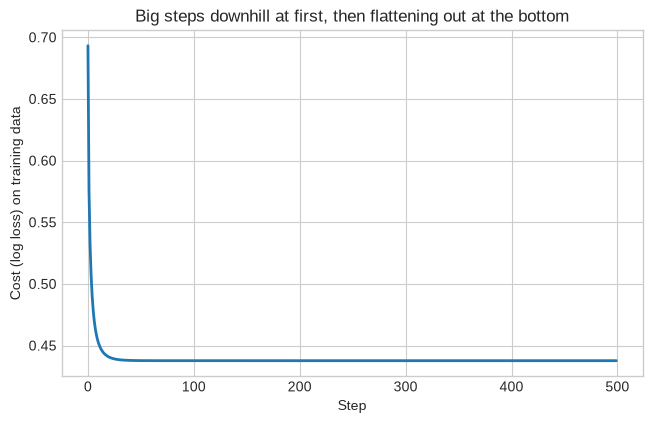

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(history, color="tab:blue", linewidth=2)
ax.set_xlabel("Step")
ax.set_ylabel("Cost (log loss) on training data")
ax.set_title("Big steps downhill at first, then flattening out at the bottom")
plt.show()

### 5.3 Watching it learn

Seven features means a bowl in eight dimensions, which cannot be drawn. So for
one picture, use a single feature — tenure — and freeze the bias at its best
value, leaving one weight $w$ to learn. Now the cost is an ordinary curve, and
each step of gradient descent is a ball rolling down it.

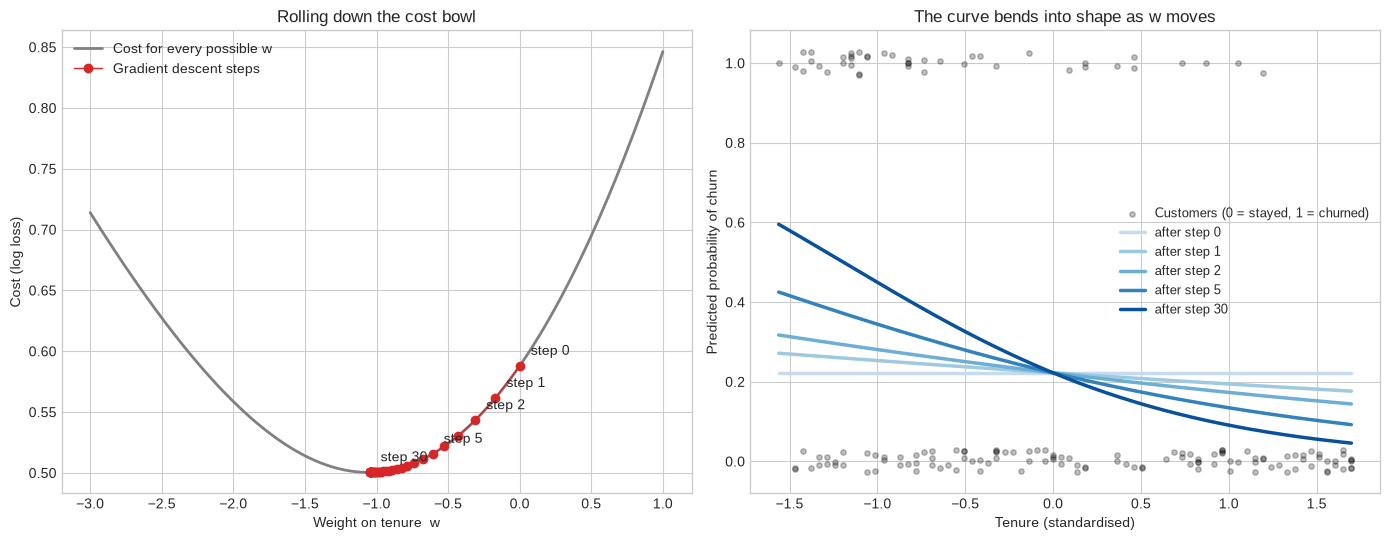

In [12]:
tenure = X_train_s[:, 0]

# The best bias for a tenure-only model, found by running the full search once.
_, b_best, _ = gradient_descent(tenure.reshape(-1, 1), y_train, alpha=1.0, n_steps=3000)

# Gradient descent on w alone, remembering where it was after each step.
w, alpha, path = 0.0, 1.0, [0.0]
for _ in range(30):
    p = sigmoid(w * tenure + b_best)
    w = w - alpha * np.mean((p - y_train) * tenure)
    path.append(w)
path = np.array(path)

w_grid = np.linspace(-3, 1, 200)
cost_grid = [log_loss_cost(sigmoid(wg * tenure + b_best), y_train) for wg in w_grid]
path_cost = [log_loss_cost(sigmoid(wp * tenure + b_best), y_train) for wp in path]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: the bowl, with the ball rolling down it.
ax1.plot(w_grid, cost_grid, color="grey", linewidth=2, label="Cost for every possible w")
ax1.plot(path, path_cost, "o-", color="tab:red", markersize=6, linewidth=1, label="Gradient descent steps")
for i in [0, 1, 2, 5, 30]:
    ax1.annotate(f"step {i}", (path[i], path_cost[i]), textcoords="offset points", xytext=(8, 8))
ax1.set_xlabel("Weight on tenure  w")
ax1.set_ylabel("Cost (log loss)")
ax1.set_title("Rolling down the cost bowl")
ax1.legend(loc="upper left")

# Right: what the model predicts at those same steps.
t_line = np.linspace(tenure.min(), tenure.max(), 200)
ax2.scatter(tenure, y_train + np.random.default_rng(RANDOM_SEED).uniform(-0.03, 0.03, len(y_train)),
            color="black", alpha=0.25, s=15, label="Customers (0 = stayed, 1 = churned)")
for i, colour in zip([0, 1, 2, 5, 30], ["#c6dbef", "#9ecae1", "#6baed6", "#3182bd", "#08519c"]):
    ax2.plot(t_line, sigmoid(path[i] * t_line + b_best), color=colour, linewidth=2.5, label=f"after step {i}")
ax2.set_xlabel("Tenure (standardised)")
ax2.set_ylabel("Predicted probability of churn")
ax2.set_title("The curve bends into shape as w moves")
ax2.legend(loc="center right", fontsize=9)

plt.tight_layout()
# Saved so README.md can show the result without anyone running this notebook.
plt.savefig("figures/result.png", dpi=150, bbox_inches="tight")
plt.show()

**Left:** at step 0, $w = 0$ and the cost is high. The first steps are big
because the slope is steep; as the ball nears the bottom, the slope flattens and
the steps shrink by themselves — nobody has to tell the algorithm to slow down.

**Right:** the same steps seen as predictions. At step 0 the curve is flat — the
model gives every customer the same probability. With each step it tilts
further, until short-tenure customers get a high churn probability and
long-tenure customers a low one.

### 5.4 Try it yourself — the learning rate

Change the values in `LEARNING_RATES` and re-run the cell. Small rates crawl.
Large rates overshoot: each step jumps past the bottom of the bowl, and the cost
bounces around or climbs instead of falling.

learning rate  0.01:  cost after 100 steps = 0.5924
learning rate   0.1:  cost after 100 steps = 0.4545
learning rate   1.0:  cost after 100 steps = 0.4377
learning rate  20.0:  cost after 100 steps = 1.9330


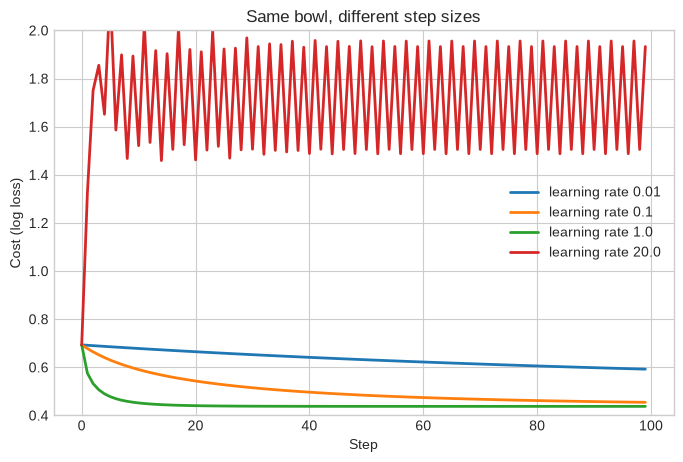

In [13]:
# Try it yourself: change these and re-run.
LEARNING_RATES = [0.01, 0.1, 1.0, 20.0]
N_STEPS = 100

fig, ax = plt.subplots(figsize=(8, 5))
for alpha in LEARNING_RATES:
    _, _, hist = gradient_descent(X_train_s, y_train, alpha=alpha, n_steps=N_STEPS)
    ax.plot(hist, linewidth=2, label=f"learning rate {alpha}")
    print(f"learning rate {alpha:>5}:  cost after {N_STEPS} steps = {hist[-1]:.4f}")

ax.set_xlabel("Step")
ax.set_ylabel("Cost (log loss)")
ax.set_ylim(0.4, 2.0)
ax.set_title("Same bowl, different step sizes")
ax.legend()
plt.show()

With the default values: 0.01 has barely started after 100 steps, 0.1 is on its
way, 1.0 reaches the bottom quickly, and 20 overshoots so badly that the cost
ends up *higher* than where it started. The right learning rate is big enough
to make progress and small enough not to jump over the valley.

### 5.5 Checking against scikit-learn

If the ten lines above are right, they should agree with scikit-learn. To compare
like with like, scikit-learn's penalty (explained next) is switched off with a
very large `C`.

In [14]:
from sklearn.linear_model import LogisticRegression

w_gd, b_gd, _ = gradient_descent(X_train_s, y_train, alpha=1.0, n_steps=5000)
LR_plain = LogisticRegression(C=1e10, max_iter=10_000).fit(X_train_s, y_train)

pd.DataFrame(
    {
        "our gradient descent": np.append(w_gd, b_gd),
        "scikit-learn": np.append(LR_plain.coef_[0], LR_plain.intercept_[0]),
    },
    index=feature_cols + ["intercept b"],
).round(3)

,our gradient descent,scikit-learn
tenure,-0.915,-0.914
age,-0.184,-0.183
address,-0.119,-0.120
income,-0.006,-0.006
ed,0.052,0.051
employ,-0.239,-0.239
equip,0.794,0.794
intercept b,-1.520,-1.518


The same weights to three decimal places. scikit-learn uses a faster search
(`lbfgs`, which also takes the curvature of the bowl into account) but it is
finding the bottom of **the same bowl**. From here on, scikit-learn does the
fitting — now with nothing hidden about what it computes.

### 5.6 scikit-learn's `C`: a penalty on large weights

scikit-learn's `LogisticRegression` adds one thing to the cost from step 4: a
penalty that grows with the size of the weights. It pulls every weight towards
zero, which stops the model from leaning too hard on any feature when data is
scarce. (A later lesson on regularisation covers this properly.)

`C` controls it — **backwards**: a *small* `C` means a *strong* pull towards
zero. The course uses `C=0.01`, which is very strong:

In [15]:
for C in [0.01, 1.0]:
    model = LogisticRegression(C=C).fit(X_train_s, y_train)
    probs = model.predict_proba(X_test_s)[:, 1]
    print(
        f"C = {C:<5}  weights: {model.coef_[0].round(2)}   "
        f"predicted churn probabilities range {probs.min():.2f} – {probs.max():.2f}"
    )

C = 0.01   weights: [-0.17 -0.09 -0.09 -0.02  0.07 -0.1   0.17]   predicted churn probabilities range 0.14 – 0.43
C = 1.0    weights: [-0.85 -0.18 -0.13 -0.01  0.06 -0.24  0.75]   predicted churn probabilities range 0.02 – 0.78


With `C=0.01` every weight is squeezed close to zero, so every customer's score
is close to the same value and every probability lands in a narrow band. The
model barely distinguishes one customer from another.

So `C` is a hyperparameter, and it is chosen as in lessons 05 and 06: **5-fold
cross-validation on the training set**, never the test set. The scaler sits
inside a `Pipeline` so each fold scales on its own training part. The score used
is log loss, because what we want from this model is good *probabilities*, and
log loss is the measure of that.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

rows = []
for C in [0.001, 0.01, 0.1, 0.3, 1, 3, 10, 100]:
    pipe = make_pipeline(StandardScaler(), LogisticRegression(C=C))
    scores = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_log_loss")
    rows.append({"C": C, "CV log loss (lower is better)": scores.mean(), "std": scores.std()})

c_results = pd.DataFrame(rows).set_index("C")
best_C = c_results["CV log loss (lower is better)"].idxmin()

print(f"Best C by cross-validation: {best_C}")
c_results.round(4)

Best C by cross-validation: 0.3


,CV log loss (lower is better),std
C,,
0.001,0.5708,0.0157
0.010,0.5191,0.0210
0.100,0.4687,0.0381
0.300,0.4671,0.0496
1.000,0.4712,0.0590
3.000,0.4739,0.0632
10.000,0.4752,0.0650
100.000,0.4758,0.0658


## 6. Results and interpretation

The model with the chosen `C`, refitted on all training customers and scored
once on the test set.

In [17]:
from sklearn import metrics
from sklearn.dummy import DummyClassifier

LR = LogisticRegression(C=best_C).fit(X_train_s, y_train)

yhat = LR.predict(X_test_s)
yhat_prob = LR.predict_proba(X_test_s)

print("predicted:", yhat[:15])
print("actual:   ", y_test[:15])
print()
print("probabilities for the first 5 customers  [P(stay), P(churn)]:")
print(yhat_prob[:5].round(3))

predicted: [0 0 0 0 0 0 0 0 1 0 0 0 0 1 0]
actual:    [0 0 1 0 1 1 1 0 1 1 0 0 0 1 0]

probabilities for the first 5 customers  [P(stay), P(churn)]:
[[0.738 0.262]
 [0.911 0.089]
 [0.821 0.179]
 [0.933 0.067]
 [0.829 0.171]]


`predict_proba` gives two columns: the probability of class 0 (stays) and of
class 1 (churns). They always add up to 1. `predict` simply answers 1 whenever
the churn probability is at least 0.5.

### Accuracy — and what to compare it with

In [18]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train_s, y_train)
baseline_acc = metrics.accuracy_score(y_test, baseline.predict(X_test_s))

# The "know nothing" probability model: give every customer the training churn rate.
churn_rate = y_train.mean()
baseline_ll = metrics.log_loss(y_test, np.full(len(y_test), churn_rate))

print(f"Test customers who churned: {y_test.sum()} of {len(y_test)}")
print()
print(f"Accuracy   — always predict 'stays':          {baseline_acc:.3f}")
print(f"Accuracy   — logistic regression:              {metrics.accuracy_score(y_test, yhat):.3f}")
print()
print(f"Log loss   — everyone gets the churn rate {churn_rate:.2f}: {baseline_ll:.3f}")
print(f"Log loss   — logistic regression:              {metrics.log_loss(y_test, yhat_prob):.3f}")

Test customers who churned: 15 of 40

Accuracy   — always predict 'stays':          0.625
Accuracy   — logistic regression:              0.725

Log loss   — everyone gets the churn rate 0.27: 0.688
Log loss   — logistic regression:              0.611


### The confusion matrix, in plain words

With two classes, the four cells of the confusion matrix have names worth
knowing. Treating **churn = 1 as the "positive" case**, because it is the one we
are trying to catch:

| | Predicted: stays | Predicted: churns |
|---|---|---|
| **Actually stayed** | True negative — correctly left alone | False positive — a false alarm |
| **Actually churned** | False negative — **a churner we missed** | True positive — a churner we caught |

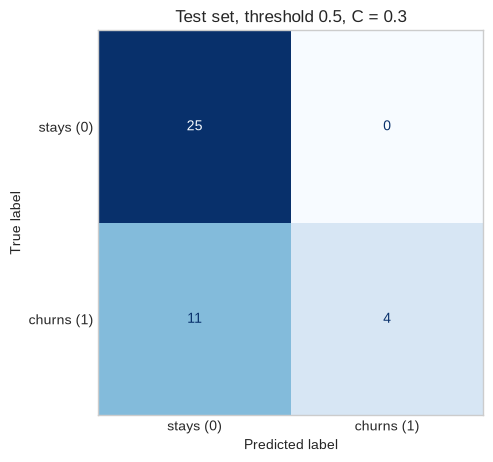

              precision    recall  f1-score   support

   stays (0)       0.69      1.00      0.82        25
  churns (1)       1.00      0.27      0.42        15

    accuracy                           0.72        40
   macro avg       0.85      0.63      0.62        40
weighted avg       0.81      0.72      0.67        40



In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, yhat, display_labels=["stays (0)", "churns (1)"], cmap="Blues", colorbar=False, ax=ax
)
ax.grid(False)
ax.set_title(f"Test set, threshold 0.5, C = {best_C}")
plt.show()

print(metrics.classification_report(y_test, yhat, target_names=["stays (0)", "churns (1)"]))

For the churn row of that report:

- **Precision** = of the customers we *flagged* as churners, how many really
  churned? $\frac{TP}{TP + FP}$ — "when the model raises an alarm, can I trust it?"
- **Recall** = of the customers who *really* churned, how many did we flag?
  $\frac{TP}{TP + FN}$ — "how many churners slip through?"
- **F1** = one number that is high only when both are high (their harmonic mean).

The course also computes the **Jaccard index**. For one class it is
$\frac{TP}{TP + FP + FN}$: the overlap between "predicted as this class" and
"really this class", divided by everything either side claims.

In [20]:
print(f"Jaccard index, churn class (1): {metrics.jaccard_score(y_test, yhat, pos_label=1):.3f}")
print(f"Jaccard index, stay class  (0): {metrics.jaccard_score(y_test, yhat, pos_label=0):.3f}")

Jaccard index, churn class (1): 0.267
Jaccard index, stay class  (0): 0.694


### Moving the threshold

`predict` uses 0.5 as the cut-off, but nothing says it has to. A retention
offer is cheap; losing a customer is expensive. So the company may well prefer
to catch more churners at the cost of some false alarms. Because the model gives
probabilities, that is a matter of **moving the threshold**, with no refitting.

In [21]:
churn_prob = yhat_prob[:, 1]

rows = []
for threshold in [0.5, 0.4, 0.3, 0.2]:
    flagged = (churn_prob >= threshold).astype(int)
    tn, fp, fn, tp = metrics.confusion_matrix(y_test, flagged).ravel()
    rows.append(
        {
            "threshold": threshold,
            "churners caught (TP)": tp,
            "churners missed (FN)": fn,
            "false alarms (FP)": fp,
            "precision": metrics.precision_score(y_test, flagged, zero_division=0),
            "recall": metrics.recall_score(y_test, flagged),
            "accuracy": metrics.accuracy_score(y_test, flagged),
        }
    )

threshold_table = pd.DataFrame(rows).set_index("threshold")
threshold_table.round(3)

,churners caught (TP),churners missed (FN),false alarms (FP),precision,recall,accuracy
threshold,,,,,,
0.5,4,11,0,1.000,0.267,0.725
0.4,4,11,2,0.667,0.267,0.675
0.3,8,7,7,0.533,0.533,0.650
0.2,11,4,11,0.500,0.733,0.625


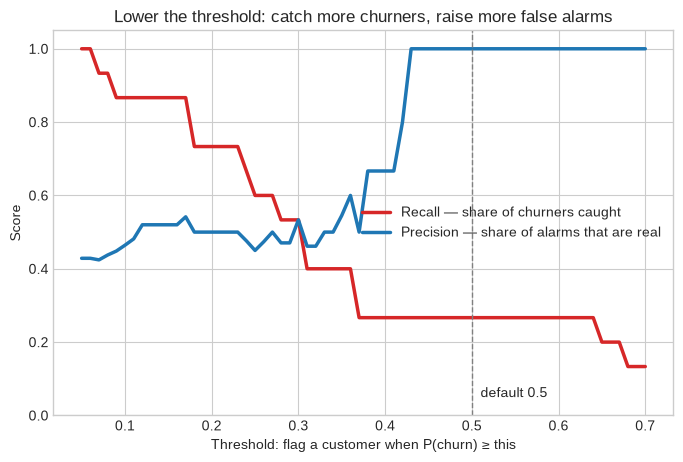

In [22]:
# Above ~0.75 no customer is flagged at all, so the range stops at 0.7.
thresholds = np.linspace(0.05, 0.7, 66)
recalls = [metrics.recall_score(y_test, (churn_prob >= t).astype(int)) for t in thresholds]
precisions = [metrics.precision_score(y_test, (churn_prob >= t).astype(int), zero_division=0) for t in thresholds]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresholds, recalls, color="tab:red", linewidth=2.5, label="Recall — share of churners caught")
ax.plot(thresholds, precisions, color="tab:blue", linewidth=2.5, label="Precision — share of alarms that are real")
ax.axvline(0.5, color="grey", linestyle="--", linewidth=1)
ax.annotate("default 0.5", (0.51, 0.05))
ax.set_xlabel("Threshold: flag a customer when P(churn) ≥ this")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("Lower the threshold: catch more churners, raise more false alarms")
ax.legend(loc="center right")
plt.savefig("figures/threshold.png", dpi=150, bbox_inches="tight")
plt.show()

### What the weights say

From step 3: each weight is the change in log-odds per unit of its feature —
here, per **one standard deviation**, because the features were standardised.
$e^{w}$ turns it into an **odds multiplier**.

In [23]:
weights = pd.DataFrame(
    {
        "weight (per 1 std)": LR.coef_[0],
        "odds multiplier  e^w": np.exp(LR.coef_[0]),
        "1 std is": scaler.scale_,
    },
    index=feature_cols,
).sort_values("weight (per 1 std)")

weights.round(3)

,weight (per 1 std),odds multiplier e^w,1 std is
tenure,-0.745,0.475,21.784
employ,-0.230,0.795,9.179
age,-0.170,0.844,13.152
address,-0.136,0.873,10.283
income,-0.021,0.979,139.965
ed,0.078,1.082,1.320
equip,0.668,1.951,0.492


### Reading the result

**Better than knowing nothing — by a modest margin.** On the 40 test customers
the model is right 72.5% of the time, against 62.5% for always answering
"stays". Its log loss is 0.611, against 0.688 for giving every customer the
same average churn rate. Both measures agree: the features carry real
information about who leaves, but not a lot.

**Forty customers is a small test.** One customer is 2.5 points of accuracy, and
the typical noise in an accuracy measured on 40 customers is about ±7 points.
The course's version, with `C=0.01`, scored 0.75 — one customer more. That
difference is noise; `C` was chosen here by cross-validation on log loss, which
is the honest way to choose it, and the test set was not consulted.

**At the default threshold the model is cautious.** It flags only 4 of the 15
churners — but all 4 are real (precision 1.0, recall 0.27). Every other churner
gets a probability below 0.5 and slips through. For a retention team that is the
wrong trade-off: a missed churner is a lost customer, while a false alarm costs
one unneeded offer.

**Moving the threshold fixes that, without refitting anything.** At 0.3 the model
catches 8 of 15 churners for 7 false alarms; at 0.2 it catches 11 of 15 for 11
false alarms. Accuracy *falls* as the threshold drops — from 0.725 to 0.625 —
while the model becomes far more useful. That is the clearest lesson here:
**accuracy is not the goal; the right threshold depends on what each kind of
mistake costs**, and only a model that outputs probabilities lets you choose it.

**What the weights say.** Read as odds multipliers per standard deviation:

- **Tenure** matters most. About 22 more months as a customer multiplies the
  odds of churning by 0.48 — roughly halves them. New customers are the ones who
  leave.
- **Equipment rental** raises churn risk. Because `equip` is 0 or 1, it is
  clearer per unit: renting equipment multiplies the odds by about
  $e^{0.668 / 0.492} \approx 3.9$.
- Longer employment, older age and more years at the same address all lower the
  odds a little. **Income** barely matters (0.98).

Two cautions, both from earlier lessons. Each multiplier assumes the *other*
features are held fixed, and tenure, age, employment and address all rise
together, so the split of credit between them is not precise (lesson 02). And
these are associations, not causes: renting equipment does not necessarily
*make* anyone leave.

**What this lesson adds to the series.** It is the first model here that cannot
be solved with a formula and has to be *searched* for. The ten-line gradient
descent in section 5 reached the same weights as scikit-learn to three decimal
places — so `LogisticRegression().fit()` is no longer a black box: it is rolling
downhill on the log-loss bowl, with a penalty on large weights added.

## 7. References

- Course: Machine Learning with Python (Jadi) — lesson on logistic regression,
  which uses this dataset and framing.
- Dataset: `ChurnData.csv`, telecom customer churn records, as supplied with the
  course.
- scikit-learn documentation: [Logistic regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression)
- scikit-learn documentation: [Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)